In [3]:
import pandas as pd

df = pd.read_excel("Amazon.xlsx")
df.head()

,OrderDate,CustomerName,ProductName,Category,Quantity,UnitPrice,TotalAmount,PaymentMethod,OrderStatus,City,Country
0,2023-01-31,Vihaan Sharma,Drone Mini,Books,3.0,106.59,319.86,Debit Card,Delivered,Washington,India
1,2023-12-30,Pooja Kumar,Microphone,Home & Kitchen,1.0,251.37,259.64,Amazon Pay,Delivered,Fort Worth,United States
2,2022-05-10,Sneha Singh,Power Bank 20000mAh,Clothing,3.0,35.03,108.06,Debit Card,Delivered,Austin,United States
3,2023-07-18,Vihaan Reddy,Webcam Full HD,Home & Kitchen,5.0,33.58,159.66,Cash on Delivery,Delivered,Charlotte,India
4,2023-02-04,Aditya Kapoor,T-Shirt,Clothing,2.0,515.64,821.36,Credit Card,Cancelled,San Antonio,Canada


In [4]:
# Import libraries for data analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df.shape

(100000, 11)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   OrderDate      100000 non-null  datetime64[ns]
 1   CustomerName   100000 non-null  object        
 2   ProductName    100000 non-null  object        
 3   Category       100000 non-null  object        
 4   Quantity       100000 non-null  float64       
 5   UnitPrice      100000 non-null  float64       
 6   TotalAmount    100000 non-null  float64       
 7   PaymentMethod  100000 non-null  object        
 8   OrderStatus    100000 non-null  object        
 9   City           100000 non-null  object        
 10  Country        100000 non-null  object        
dtypes: datetime64[ns](1), float64(3), object(7)
memory usage: 8.4+ MB


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   OrderDate      100000 non-null  datetime64[ns]
 1   CustomerName   100000 non-null  object        
 2   ProductName    100000 non-null  object        
 3   Category       100000 non-null  object        
 4   Quantity       100000 non-null  float64       
 5   UnitPrice      100000 non-null  float64       
 6   TotalAmount    100000 non-null  float64       
 7   PaymentMethod  100000 non-null  object        
 8   OrderStatus    100000 non-null  object        
 9   City           100000 non-null  object        
 10  Country        100000 non-null  object        
dtypes: datetime64[ns](1), float64(3), object(7)
memory usage: 8.4+ MB


In [8]:
df.describe()

,Quantity,UnitPrice,TotalAmount
count,100000.000000,100000.000000,100000.000000
mean,3.001400,302.905748,918.256479
std,1.413548,171.840797,724.508332
min,1.000000,5.000000,4.270000
25%,2.000000,154.190000,340.890000
50%,3.000000,303.070000,714.315000
75%,4.000000,451.500000,1349.765000
max,5.000000,599.990000,3534.980000


In [9]:
df.isnull().sum()

OrderDate        0
CustomerName     0
ProductName      0
Category         0
Quantity         0
UnitPrice        0
TotalAmount      0
PaymentMethod    0
OrderStatus      0
City             0
Country          0
dtype: int64

In [10]:
df = df.drop_duplicates()

In [11]:
df.dtypes

OrderDate        datetime64[ns]
CustomerName             object
ProductName              object
Category                 object
Quantity                float64
UnitPrice               float64
TotalAmount             float64
PaymentMethod            object
OrderStatus              object
City                     object
Country                  object
dtype: object

In [12]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'], errors='coerce')

In [13]:
df['OrderDate'].isnull().sum()

0

In [14]:
df.duplicated().sum()

0

In [15]:
df.dtypes

OrderDate        datetime64[ns]
CustomerName             object
ProductName              object
Category                 object
Quantity                float64
UnitPrice               float64
TotalAmount             float64
PaymentMethod            object
OrderStatus              object
City                     object
Country                  object
dtype: object

In [16]:
df['OrderDate'].isnull().sum()

0

In [17]:
total_sales = df['TotalAmount'].sum()
print("Total Sales:", total_sales)

Total Sales: 91825647.92


In [18]:
total_quantity = df['Quantity'].sum()
print("Total Quantity Sold:", total_quantity)

Total Quantity Sold: 300140.0


In [19]:
total_orders = len(df)
print("Total Records:", total_orders)

Total Records: 100000


In [20]:
product_sales = df.groupby('ProductName')['Quantity'].sum()

product_sales = product_sales.sort_values(ascending=False)

product_sales.head(5)

ProductName
LED Desk Lamp        6344.0
Water Bottle         6275.0
Memory Card 128GB    6240.0
Router               6202.0
Board Game           6200.0
Name: Quantity, dtype: float64

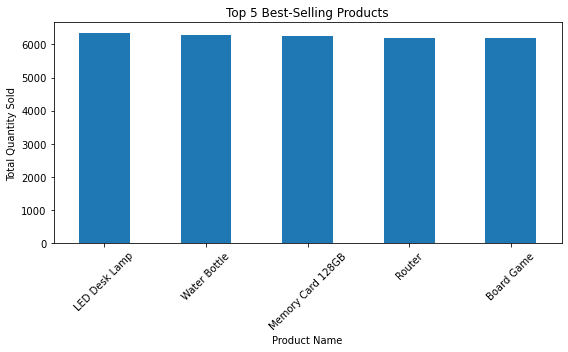

In [21]:
top_products = df.groupby('ProductName')['Quantity'].sum()

top_products = top_products.sort_values(ascending=False).head(5)

top_products.plot(kind='bar', figsize=(8, 5))

plt.title('Top 5 Best-Selling Products')
plt.xlabel('Product Name')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
category_sales = df.groupby('Category')['TotalAmount'].sum()

category_sales = category_sales.sort_values(ascending=False)

category_sales

Category
Electronics          15584217.18
Sports & Outdoors    15345571.88
Books                15261837.01
Clothing             15253397.50
Toys & Games         15216684.99
Home & Kitchen       15163939.36
Name: TotalAmount, dtype: float64

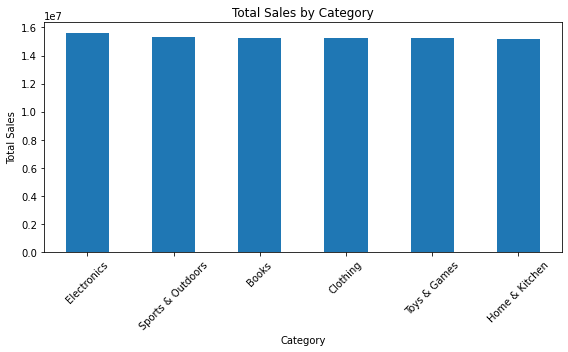

In [23]:
category_sales.plot(kind='bar', figsize=(8, 5))

plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:
df['Month'] = df['OrderDate'].dt.to_period('M')

In [25]:
monthly_sales = df.groupby('Month')['TotalAmount'].sum()

monthly_sales

Month
2020-01    1637069.40
2020-02    1339388.21
2020-03    1587125.66
2020-04    1588347.29
2020-05    1533834.17
2020-06    1500269.29
2020-07    1552981.94
2020-08    1640874.93
2020-09    1554682.21
2020-10    1515403.62
2020-11    1502232.24
2020-12    1577655.06
2021-01    1575253.23
2021-02    1425365.99
2021-03    1484165.89
2021-04    1470885.02
2021-05    1571842.25
2021-06    1593398.08
2021-07    1596668.40
2021-08    1545324.30
2021-09    1534912.30
2021-10    1511118.44
2021-11    1419480.77
2021-12    1520160.14
2022-01    1609759.87
2022-02    1369866.29
2022-03    1589809.35
2022-04    1515497.24
2022-05    1527845.26
2022-06    1533829.81
2022-07    1556516.29
2022-08    1541701.50
2022-09    1457859.60
2022-10    1534349.51
2022-11    1525937.46
2022-12    1604276.23
2023-01    1567772.07
2023-02    1384957.09
2023-03    1557146.56
2023-04    1560322.12
2023-05    1588151.65
2023-06    1485367.09
2023-07    1562298.78
2023-08    1585424.79
2023-09    1543306.82
2023

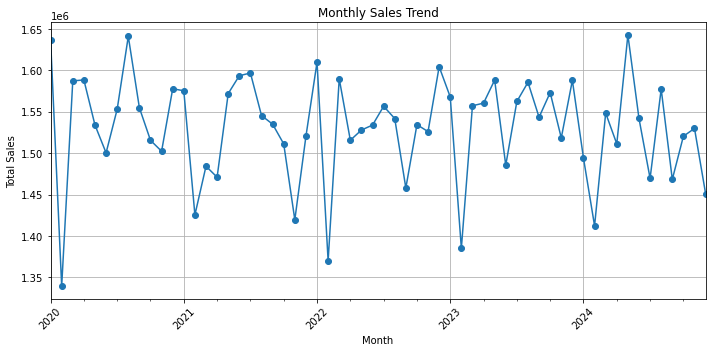

In [26]:
monthly_sales.plot(kind='line', marker='o', figsize=(10, 5))

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
payment_counts = df['PaymentMethod'].value_counts()

payment_counts

Credit Card         35038
Debit Card          20024
UPI                 15066
Amazon Pay          15017
Net Banking          9927
Cash on Delivery     4928
Name: PaymentMethod, dtype: int64

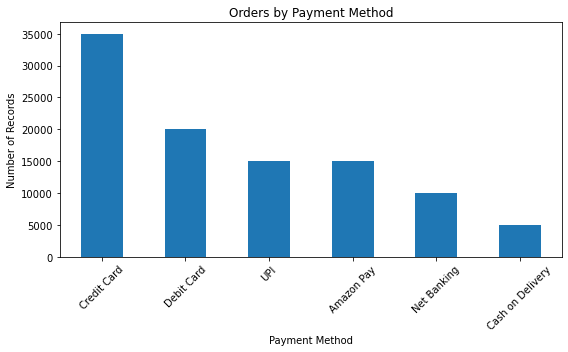

In [28]:
payment_counts.plot(kind='bar', figsize=(8, 5))

plt.title('Orders by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Records')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
status_counts = df['OrderStatus'].value_counts()

status_counts

Delivered    74628
Shipped      15192
Pending       4103
Returned      3049
Cancelled     3028
Name: OrderStatus, dtype: int64

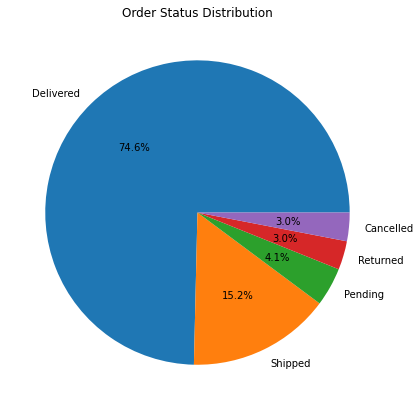

In [30]:
status_counts.plot(kind='pie', autopct='%1.1f%%', figsize=(7, 7))

plt.title('Order Status Distribution')
plt.ylabel('')
plt.show()

In [31]:
city_sales = df.groupby('City')['TotalAmount'].sum()

city_sales = city_sales.sort_values(ascending=False)

city_sales.head(10)

City
Charlotte       4747701.73
Dallas          4730108.67
San Jose        4669614.33
Seattle         4660962.17
Philadelphia    4650673.88
Denver          4638498.97
Austin          4638403.18
Chicago         4632847.44
Los Angeles     4620629.78
Columbus        4615442.32
Name: TotalAmount, dtype: float64

In [32]:
customer_sales = df.groupby('CustomerName')['TotalAmount'].sum()

customer_sales = customer_sales.sort_values(ascending=False)

customer_sales.head(10)

CustomerName
Pooja Kapoor    547832.64
Vihaan Singh    526675.89
Pooja Singh     516451.45
Kabir Joshi     515361.68
Aditya Gupta    515005.09
Mohit Singh     513513.19
Sunita Mehta    511642.91
Aman Reddy      511236.91
Karan Singh     510900.60
Simran Singh    509337.35
Name: TotalAmount, dtype: float64

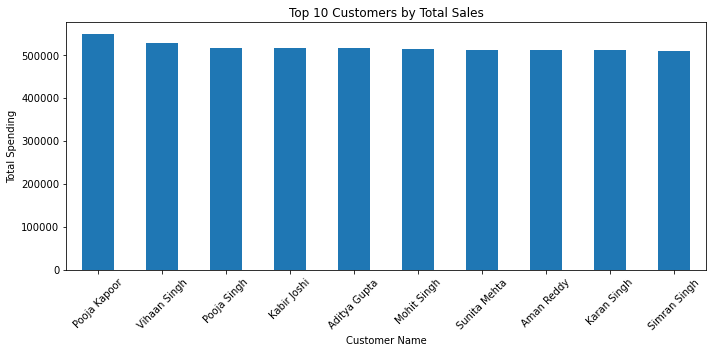

In [33]:
customer_sales.head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Top 10 Customers by Total Sales')
plt.xlabel('Customer Name')
plt.ylabel('Total Spending')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [34]:
print("Total Revenue:", df['TotalAmount'].sum())
print("Total Units Sold:", df['Quantity'].sum())
print("Average Order Value:", df['TotalAmount'].mean())
print("Unique Customers:", df['CustomerName'].nunique())
print("Unique Products:", df['ProductName'].nunique())

Total Revenue: 91825647.92
Total Units Sold: 300140.0
Average Order Value: 918.2564792000006
Unique Customers: 200
Unique Products: 50


In [ ]:
Business Insights and Conclusion

 Key Analysis Performed
- Analyzed overall sales revenue and quantity sold.
- Identified the top 5 best-selling products.
- Compared sales performance across product categories.
- Analyzed monthly sales trends.
- Examined customer payment methods and order statuses.
- Identified the highest-revenue cities.
- Analyzed top customers by total recorded spending.

 Conclusion
This project uses Python, Pandas, Matplotlib, and Seaborn to analyze sales data and identify useful business insights. The analysis helps understand product performance, sales trends, customer purchasing behavior, and geographic sales distribution.

Tools and Technologies
- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn